In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_trend_rolling(data, time, min_len):
    """
    计算数据的滚动趋势

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势

    Returns:
    trend_map : 二维数组，包含滚动趋势
    time_map : 二维数组，包含对应的时间映射
    """
    len_amp = len(data)
    # trend_amp [[p, b], rolling]    time_map [start_time, end_time]
    trend_map = np.full((len_amp - min_len, 2), np.nan)
    time_map = np.full((len_amp - min_len, 2), np.nan)

    for i in range(len_amp - min_len):
        amp_now = data[i:i + min_len]
        trend_result = trend_window(amp_now, min_len, cal_type=0, mk_type=1).squeeze()
        trend_map[i] = trend_result
        time_map[i] = [time[i], time[i + min_len]]

    return trend_map, time_map

In [3]:
# part1 计算Trendy CFE Climate LULCC的Acc空间分布
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-Trendy/'
files = os.listdir(folder)
files.sort()
part1_dict = {}
exp_list_origion = ['S0', 'S1', 'S2', 'S3']
exp_list = ['Control', 'CFE', 'Climate', 'LULCC']
min_len = 20
trend_select = 7
count_diff = np.sum(np.arange(1, trend_select + 1))

for file in files:
    model = file.split('.')[0]
    if model == 'CLM5':
        model = 'CLM5.0'
    ds = xr.open_dataset(os.path.join(folder, file))
    time_raw = ds['time'].values
    valid_idx = (time_raw >= 1979) & (time_raw <= 2021)
    
    # 应用截取掩码 (假设时间维度在 axis=1)
    amp_grid = ds['amp_cum_grid'].values[:, valid_idx, :, :]
    amp_region = ds['amp_cum_region'].values[:, valid_idx]
    time = time_raw[valid_idx]

    # 分离exp
    amp_grid_temp = np.zeros_like(amp_grid)
    amp_region_temp = np.zeros_like(amp_region)

    amp_grid_temp[0] = amp_grid[-1]     # control
    amp_region_temp[0] = amp_region[-1]
    amp_grid_temp[1] = amp_grid[1]      # CFE
    amp_region_temp[1] = amp_region[1]
    amp_grid_temp[2] = amp_grid[2] - amp_grid[1] # Climate
    amp_region_temp[2] = amp_region[2] - amp_region[1]
    amp_grid_temp[3] = amp_grid[3] - amp_grid[2] # LULCC
    amp_region_temp[3] = amp_region[3] - amp_region[2]

    part1_dict[model] = {
        'amp_cum_grid': amp_grid_temp,
        'amp_cum_region': amp_region_temp,
        'time': ds['time'].values,
        'lon': ds['lon'].values,
        'lat': ds['lat'].values
    }
    lon = ds['lon'].values
    lat = ds['lat'].values
    ds.close()

# 计算Acc
tasks = []
tasks_index = []
for model, info in part1_dict.items():
    if model != 'Trendy': # 只计算Trendy的对比实验
        continue
    amp_grid = info['amp_cum_grid']
    time = info['time']
    
    for num_exp, exp in enumerate(exp_list):
        for i in range(amp_grid.shape[-2]):
            if lat[i] < 50:
                continue
            for j in range(amp_grid.shape[-1]):
                tasks.append((amp_grid[num_exp, :, i, j], time, min_len, trend_select))
                tasks_index.append((model, num_exp, i, j))

pool = Pool(processes=cpu_count()-2)
results = pool.map(process_trend_diff, tasks)
pool.close()

amp_grid = part1_dict['Trendy']['amp_cum_grid']
nlat, nlon = amp_grid.shape[-2], amp_grid.shape[-1]

for model in part1_dict.keys():
    part1_dict[model]['diff_grid']   = np.full((len(exp_list), count_diff, nlat, nlon), np.nan)
    part1_dict[model]['sign_grid']   = np.full((len(exp_list), nlat, nlon), np.nan)
    part1_dict[model]['p_diff_grid'] = np.full((len(exp_list), nlat, nlon), np.nan)
    part1_dict[model]['diff_region'] = np.full((len(exp_list), count_diff), np.nan)
    part1_dict[model]['sign_region'] = np.full((len(exp_list)), np.nan)
    part1_dict[model]['p_diff_region'] = np.full((len(exp_list)), np.nan)
    
    for e, exp in enumerate(exp_list):
        amp_region = part1_dict[model]['amp_cum_region'][e]
        diff_region, sign_region, p_diff_region = cal_trend_diff(amp_region, part1_dict[model]['time'], min_len, trend_select)
        part1_dict[model]['diff_region'][e] = diff_region
        part1_dict[model]['sign_region'][e] = sign_region
        part1_dict[model]['p_diff_region'][e] = p_diff_region

for idx, res in enumerate(results):
    model, num_exp, i, j = tasks_index[idx]
    diff, sign, p_diff = res
    part1_dict[model]['diff_grid'][num_exp, :, i, j] = diff
    part1_dict[model]['sign_grid'][num_exp, i, j] = sign
    part1_dict[model]['p_diff_grid'][num_exp, i, j] = p_diff

In [4]:
## 海洋mask网格
shapefile_path = '/public/home/zhujw/work/guoly/data/SHP/ne_110m_land/ne_110m_land.shp'
lat_lim = 50
gdf = gpd.read_file(shapefile_path)

for model in part1_dict.keys():
    lat = part1_dict[model]['lat']
    lon = part1_dict[model]['lon']
    index = np.where(lat == lat_lim)[0][0]
    lat = lat[index:]
    lon_grid, lat_grid = np.meshgrid(lon, lat)

    points = [Point(x, y) for x, y in zip(lon_grid.ravel(), lat_grid.ravel())]
    grid_gdf = gpd.GeoDataFrame(geometry=points, crs="EPSG:4326")

    mask = grid_gdf.geometry.apply(lambda x: any(gdf.contains(x)))
    mask_2d = mask.values.reshape(lat_grid.shape)

    # 额外：去掉格陵兰（经纬度粗略范围）
    greenland_mask = (
        (lon_grid >= -75) & (lon_grid <= -10) &
        (lat_grid >= 60)  & (lat_grid <= 85)
    )
    mask_2d[greenland_mask] = False

    part1_dict[model]['land_mask'] = mask_2d

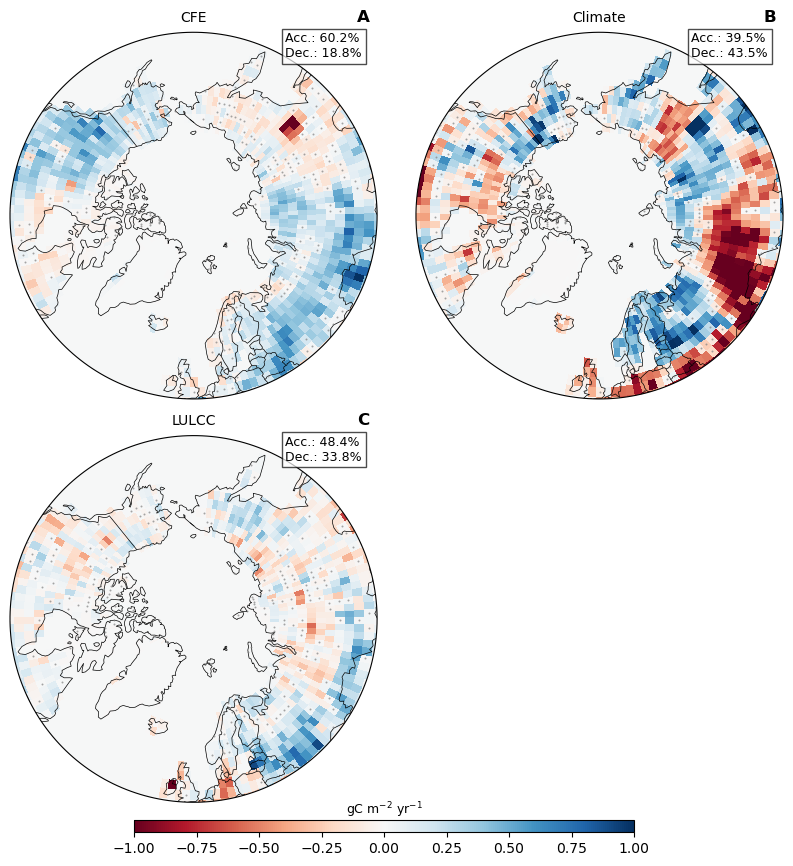

In [5]:
## 绘图
fig = plt.figure(figsize=(10, 10))
gs = gridspec.GridSpec(2, 2, width_ratios=[1]*2, height_ratios=[1]*2, wspace=0.1, hspace=0.1)
axs = np.empty((2, 2), dtype=object)
alpha = 0.7
vmax_value = 1
for i in range(3):
    ax = axs[i%2, i//2]
    ax = fig.add_subplot(gs[i%2, i//2], projection=ccrs.NorthPolarStereo(central_longitude=0))
    ax.set_extent([-180, 180, lat_lim, 90], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    theta = np.linspace(0, 2*np.pi, 240)
    r = 0.5
    verts = np.vstack([0.5 + r*np.cos(theta), 0.5 + r*np.sin(theta)]).T
    circle_path = mpath.Path(verts)
    ax.set_boundary(circle_path, transform=ax.transAxes)
    axs[i%2, i//2] = ax

# region Part1
for num_exp, exp in enumerate(exp_list[1:]):
    ax = axs[num_exp//2, num_exp%2]
    ax.text(0.5, 1.02, exp, fontsize=10,
            ha='center', va='bottom', transform=ax.transAxes)
    info = part1_dict['Trendy']
    lon = info['lon']
    lat = info['lat']
    mask_2d = info['land_mask']
    index = np.where(lat == lat_lim)[0][0]
    lat = lat[index:]
    diff_grid = info['diff_grid'][num_exp+1]
    sign_grid = info['sign_grid'][num_exp+1]
    p_diff_grid = info['p_diff_grid'][num_exp+1]
    trend_data = diff_grid[:, index:, :].mean(axis=0) * 1e15 # PgC m-2 y-1 to gC m-2 y-1
    sign_start = sign_grid[index:]
    p_value = p_diff_grid[index:]

    # mask网格
    mask = np.where(np.logical_or(p_value > 0.1, sign_start < 0), 1, np.nan)  # 显著性掩码
    all_mask = mask.copy()
    all_mask = np.where(mask_2d, all_mask, np.nan)
    area = cal_area_grid(lat, lon)

    # 标注加速/减速百分比
    acc_percent = 0
    dec_percent = 0
    total_count = 0
    for i in range(trend_data.shape[0]):
        for j in range(trend_data.shape[1]):
            if not mask_2d[i, j]:
                continue
            total_count += area[i, j]
            if np.logical_and(p_value[i, j] <= 0.1, sign_start[i, j] > 0):
                if trend_data[i, j] >= 0:
                    acc_percent += area[i, j]
                elif trend_data[i, j] < 0:
                    dec_percent += area[i, j]
    total_percent = acc_percent + dec_percent
    acc_percent = acc_percent / total_count * 100
    dec_percent = dec_percent / total_count * 100
    ax.text(0.75, 1, f'Acc.: {acc_percent:.1f}%\nDec.: {dec_percent:.1f}%', 
            transform=ax.transAxes, ha='left', va='top', fontsize=9,
            bbox=dict(boxstyle='square', facecolor='white', alpha=alpha, 
                        edgecolor='black', linestyle='-'))

    # 绘图
    im = ax.pcolormesh(lon, lat, trend_data, cmap='RdBu', vmin=-vmax_value, vmax=vmax_value, 
                        transform=ccrs.PlateCarree())

    # 标注不显著区域
    mask_points = np.isfinite(all_mask) & (all_mask == 1)
    if np.any(mask_points):
        lon2d, lat2d = np.meshgrid(lon, lat)
        ax.scatter(lon2d[mask_points], lat2d[mask_points],
                    s=2, c='gray', marker='o', alpha=alpha,
                    transform=ccrs.PlateCarree(), zorder=5, linewidths=0, rasterized=True)
        
letters = ['A', 'B', 'C']
for i in range(3):
    axs[i//2, i%2].text(0.98, 1.02, letters[i], va='bottom', ha='right',
                    fontsize=12, transform=axs[i//2, i%2].transAxes, fontweight='bold')

cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.012])  # [left, bottom, width, height]
chars = cm.ScalarMappable(norm=Normalize(vmin=-vmax_value, vmax=vmax_value), cmap='RdBu')
chars.set_array([])  # 必要占位，不存实际数据
cbar = fig.colorbar(chars, cax=cbar_ax, orientation='horizontal')
cbar_ax.text(0.5, 1.02, 'gC m$^{-2}$ yr$^{-1}$', fontsize=9, 
             ha='center', va='bottom', transform=cbar_ax.transAxes)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-5-Trendy-diff-map.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)